# 1. Sean $Y_1, Y_2, ...$ variables aleatorias independientes e idénticamente distribuidas tales que

# $$\mathbb{P}(Y_i = 1) = \mathbb{P}(Y_i = -1) = \frac{1}{2}.$$

# Considera la caminata aleatoria simple y simétrica definida por

# $$S_0 = 0, \qquad S_n = \sum_{i=1}^{n} Y_i.$$

# Para $T > 0$, definimos el proceso reescalado

# $$W_n(t) = \sqrt{\frac{T}{n}}\, S_{\lfloor nt/T \rfloor}, \qquad t \in [0, T].$$

# Realiza lo siguiente:

## (a) Obtén la esperanza, la varianza y la función de covarianza del proceso $W_n(t)$. Muestra que, para cualesquiera $s, t \in [0, T]$,

## $$ \lim_{n \to \infty} \mathbb{E}[W_n(t)] = 0$$
## $$\lim_{n \to \infty} \mathrm{Cov}(W_n(s), W_n(t)) = \min(s, t).$$

La esperanza será

$$\mathbb{E}[W_n(t)] = \mathbb{E}[\sqrt{\frac{T}{n}} S_{⌊\frac{nt}{T}⌋}] = \sqrt{\frac{T}{n}} \mathbb{E}[S_{⌊\frac{nt}{T}⌋}] = \sqrt{\frac{T}{n}} \sum\limits_{i=1}^{⌊\frac{nt}{T}⌋} \mathbb{E}[Y_i].$$

Pero $\mathbb{E}[Y_i] = 1(\frac{1}{2})-1(\frac{1}{2}) = 0$, entonces

$$\mathbb{E}[W_n(t)] = 0.$$

Ahora, como $\mathbb{E}[W_n(t)] = 0$, entonces si tomamos $s \leq t$ la covarianza será

$$\mathbb{Cov}(W_n(s), W_n(t)) = \mathbb{E}[W_n(s) W_n(t)] = \mathbb{E}[\frac{T}{n}S_{⌊\frac{ns}{T}⌋} S_{⌊\frac{nt}{T}⌋}] = \frac{T}{n} \mathbb{E}[S_{⌊\frac{ns}{T}⌋} S_{⌊\frac{nt}{T}⌋}] = $$
$$\frac{T}{n} \mathbb{E}[S_{⌊\frac{ns}{T}⌋} (S_{⌊\frac{ns}{T}⌋} + (S_{⌊\frac{nt}{T}⌋} - S_{⌊\frac{ns}{T}⌋}))] = \frac{T}{n} \mathbb{E}[S_{⌊\frac{ns}{T}⌋} S_{⌊\frac{ns}{T}⌋} + S_{⌊\frac{ns}{T}⌋} (S_{⌊\frac{nt}{T}⌋} - S_{⌊\frac{ns}{T}⌋})] = $$
$$\frac{T}{n} (\mathbb{E}[S_{⌊\frac{ns}{T}⌋} S_{⌊\frac{ns}{T}⌋}] + \mathbb{E}[S_{⌊\frac{ns}{T}⌋} (S_{⌊\frac{nt}{T}⌋} - S_{⌊\frac{ns}{T}⌋})]) = \frac{T}{n} (\mathbb{Var}(S_{⌊\frac{ns}{T}⌋}) + \mathbb{E}[S_{⌊\frac{ns}{T}⌋} (S_{⌊\frac{nt}{T}⌋} - S_{⌊\frac{ns}{T}⌋})]).$$

Ahora como $S_{⌊\frac{ns}{T}⌋}$ solo depende de $Y_1, ... Y_s$ y $(S_{⌊\frac{nt}{T}⌋} - S_{⌊\frac{ns}{T}⌋})$ solo depende de $Y_{s+1}, ...,Y_{t}$. Pero como las $Y_i$ son independientes, entonces $S_{⌊\frac{ns}{T}⌋}$ y $(S_{⌊\frac{nt}{T}⌋} - S_{⌊\frac{ns}{T}⌋})$, tambien lo son con lo cual

$$\mathbb{Cov}(W_n(s), W_n(t)) = \frac{T}{n} \mathbb{Var}(S_{⌊\frac{ns}{T}⌋}) = \frac{T}{n} \mathbb{Var}(\sum\limits_{i = 1}^{⌊\frac{ns}{T}⌋}Y_i) = \frac{T}{n} \sum\limits_{i = 1}^{⌊\frac{ns}{T}⌋}\mathbb{Var}(Y_i).$$

Pero como $\mathbb{Var}(Y_i) = \mathbb{E}[Y_i^2] = 1(1) = 1$, entonces

$$\mathbb{Cov}(W_n(s), W_n(t)) = \frac{T}{n}⌊\frac{ns}{T}⌋.$$

Ahora sabemos que

$$\frac{T}{n}⌊\frac{ns}{T}⌋(\frac{ns}{T} - 1) \leq \frac{T}{n}⌊\frac{ns}{T}⌋ \leq \frac{T}{n}\frac{ns}{T}$$
$$⇒ s - \frac{T}{n} \leq \frac{T}{n}⌊\frac{ns}{T}⌋ \leq s.$$

Así tomando el limite tenemos que

$$\lim\limits_{n \to ∞} \mathbb{Cov}(W_n(s), W_n(t)) = s$$

Para $s \leq t$.

## (b) Implementa un algoritmo que permita simular trayectorias del proceso $W_n(t)$. Para $T = 1$, genera trayectorias considerando $n = 10, 100, 1000, 10000$ y compáralas gráficamente con trayectorias de un movimiento Browniano estándar. Discute las diferencias que observas conforme aumenta $n$.

In [4]:
import numpy as np
import matplotlib.pyplot as plt


def W_n_t(n, T = 1, seed = None):
  if seed is not None:
    np.random.seed(seed)
  Y = np.random.choice([-1, 1], size = n)
  S = np.insert(np.cumsum(Y), 0, 0)
  t = np.linspace(0, T, n + 1)
  piso = np.floor(n*t/T).astype(int)
  W = np.sqrt(T / n) * S[piso]
  return W

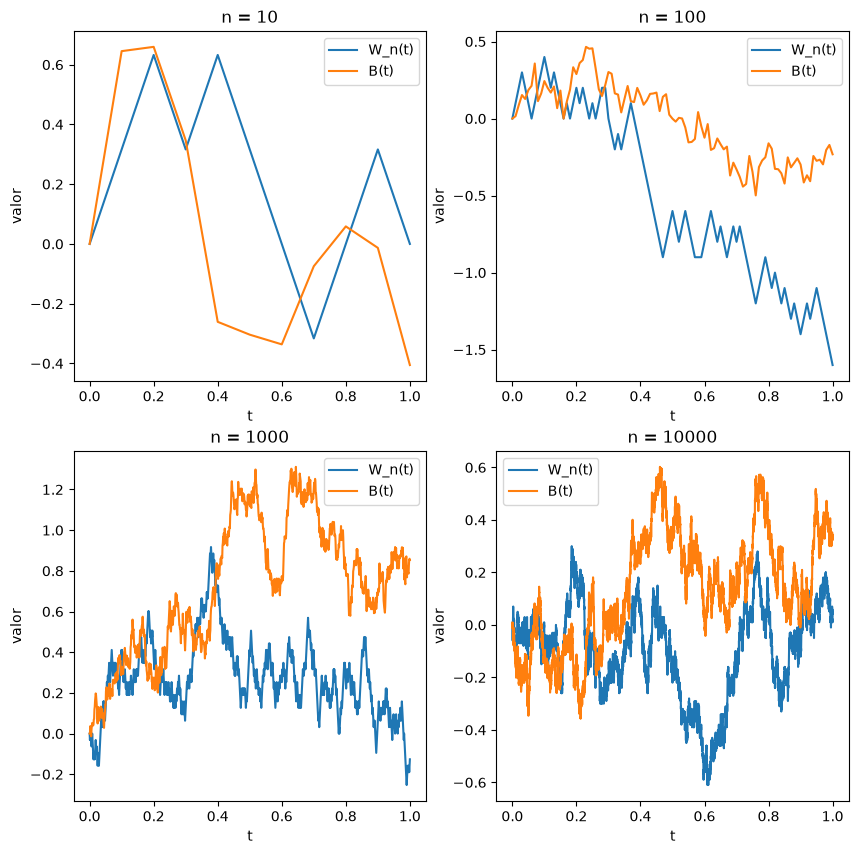

In [5]:
n = [10, 100, 1000, 10000]
T = 1

def browniano_estandar(n, T = 1, seed = None):
  if seed is not None:
    np.random.seed(seed)
  Z = np.sqrt(T/n) * np.random.randn(n)
  B = np.insert(np.cumsum(Z), 0, 0)
  return B

np.random.seed(29)

W = [W_n_t(i, T) for i in n]
B = [browniano_estandar(i, T) for i in n]

fig, ax = plt.subplots(2, 2, figsize = (10, 10))
for i in range(2):
    for j in range(2):
        k = 2*i + j
        t = np.linspace(0, T, n[k] + 1)
        ax[i, j].plot(t, W[k], label='W_n(t)')
        ax[i, j].plot(t, B[k], label='B(t)')
        ax[i, j].legend()
        ax[i, j].set_title(f'n = {n[k]}')
        ax[i, j].set_xlabel('t')
        ax[i, j].set_ylabel('valor')
plt.show()

Para n pequeña si hay diferencia entre los procesos, en la simulacion del proceso browniano estandar. Los incrementos, no tienen una escala fija, es decir $|B(t_i) - B(t_{i-1})|$ es distinto para cada i, pues $|B(t_i) - B(t_{i-1})| = |\sqrt{\frac{1}{n}}Z_i|$. Mientra que $|W_n(t_i) - W_n(t_{i-1})| = |\sqrt{\frac{1}{n}} Y_i| = \sqrt{\frac{1}{n}}$, sí que para n pequeña, se pueden notar bastante la diferencia, pero para n grande, ya no se ve gran diferencia.

## (c) Utilizando el teorema central del límite, justifica que para cualquier $t \in (0, T]$,

## $$W_n(t) \xrightarrow{d} N(0, t).$$

## Realiza un estudio de simulación que permita ilustrar esta convergencia para distintos valores de $n$. Compara las distribuciones empíricas obtenidas con la distribución normal correspondiente.

Por teorema central del limite tenemos que

$$\frac{\sum\limits_{i=1}^{m} X_i - mμ}{\sqrt{m}\sigma} \xrightarrow{d} \text{N}(0,1).$$

Tomemos $X_i = Y_i$ y $m = \lfloor \frac{nt}{T} \rfloor$, entonces

$$\frac{\sum\limits_{i=1}^{\lfloor \frac{nt}{T} \rfloor} Y_i}{\sqrt{\lfloor \frac{nt}{T} \rfloor}} = \frac{S_{\lfloor \frac{nt}{T} \rfloor}}{\sqrt{\lfloor \frac{nt}{T} \rfloor}} \xrightarrow{d} \text{N}(0,1).$$

Ahora si multiplicamos por $\sqrt{\frac{T}{n}} \sqrt{\lfloor \frac{nt}{T}\rfloor}$, entonces

$$\lim\limits_{n \to \infty} W_n(t) = \lim\limits_{n \to \infty} \sqrt{\frac{T}{n}} S_{\lfloor \frac{nt}{T} \rfloor} = \lim\limits_{n \to \infty} \sqrt{\frac{T}{n}} \sqrt{\lfloor \frac{nt}{T}\rfloor} \frac{S_{\lfloor \frac{nt}{T} \rfloor}}{\sqrt{\lfloor \frac{nt}{T} \rfloor}} = \sqrt{t} \lim\limits_{n \to \infty} \frac{S_{\lfloor \frac{nt}{T} \rfloor}}{\sqrt{\lfloor \frac{nt}{T} \rfloor}} = \sqrt{t} N,$$

donde $N \sim \text{N}(0,1)$, así $\lim\limits_{n \to \infty} W_n(t) \sim \text{N}(0,t).$

## (d) Considera el máximo del proceso reescalado,

## $$M_n = \max_{0 \le t \le T} W_n(t).$$

## Para $T = 1$, simula $N = 1000$ realizaciones de $M_n$ para distintos valores de $n$ y compara su distribución empírica con la distribución del máximo de un movimiento Browniano estándar, cuya función de distribución está dada por

## $$\mathbb{P}\left(\sup_{0 \le t \le 1} B_t \le x\right) = 2\Phi(x) - 1, \qquad x \ge 0.$$

## ¿Qué puedes concluir sobre el comportamiento de los máximos conforme $n$ aumenta?

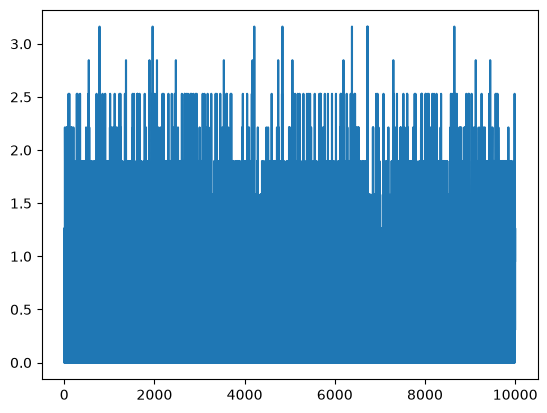

array([0.63245553, 1.26491106, 0.        , ..., 0.9486833 , 1.26491106,
       0.31622777], shape=(10000,))

In [6]:
N = 10000
T = 1

def M_n(n, N, T = 1, seed = None):
    if seed != None:
        np.random.seed(seed)
    M = np.zeros(N)
    for i in range(N):
        M[i] = max(W_n_t(n, T))
    return M

M = M_n(10, N, T, seed = 29)
plt.plot(range(1, N + 1), M)
plt.show()
M

In [7]:
def F_M_n(x, M):
    return np.sum(M <= x) / len(M)

In [8]:
from scipy.stats import norm

n = [10, 100, 500, 1000]
x = np.linspace(0, 3, 20)
F_M = np.zeros((len(n), len(x)))
F = np.zeros(len(x))


for k, j in enumerate(x):
    F[k] = 2 * norm.cdf(j) - 1
    for i in n:
        F_M[n.index(i), k] = F_M_n(j, M_n(i, N, T, seed = 29))


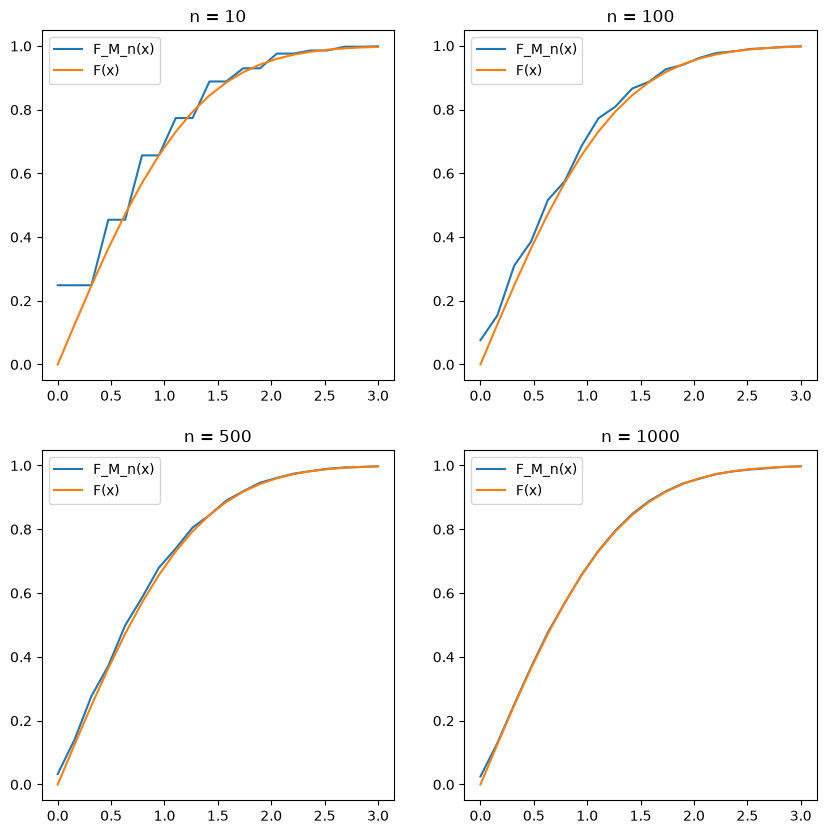

In [9]:
fig, ax = plt.subplots(2, 2, figsize = (10, 10))
for i in range(2):
    for j in range(2):
        k = 2*i + j
        ax[i, j].plot(x, F_M[k], label=f'F_M_n(x)')
        ax[i, j].plot(x, F, label='F(x)')
        ax[i, j].legend()
        ax[i, j].set_title(f'n = {n[k]}')
plt.show()

Esto nos muestra que el comportamiento de de $M_n$ es muy similar al de maximo del browniano, dado que sus distribuciones lo son. Parecería que converge a la distribucion del maximo del browniano

# 2. Sea $\{B_t : t \geq 0\}$ un movimiento Browniano estándar. Considera el proceso obtenido al condicionar $B_T = b - a$, y trasladar la trayectoria de manera que comience en $a$, donde $a, b \in \mathbb{R}$ y $T > 0.$

# Realiza lo siguiente:

## (a) Considera una partición $0 = t_0 < t_1 < \cdots < t_n = T$. Utilizando las propiedades de la distribución normal multivariada, muestra que la distribución condicional de

## $$(a + B_{t_1}, \ldots, a + B_{t_{n-1}}) \mid B_T = b - a$$

## es normal multivariada con vector de medias

## $$m(t_i) = a + \frac{b - a}{T}\, t_i,$$

## y matriz de covarianzas cuyas entradas están dadas por

## $$K(t_i, t_j) = \min(t_i, t_j) - \frac{t_i t_j}{T}.$$

Como sabemos que $(B_{t_1}, B_{t_2}, ..., B_{t_n} = B_T) \sim \text{N}(0, \Sigma)$ donde $ \Sigma_{i,j} = \min\{t_i, t_j\}$. Entonces $(B_{t_1}, B_{t_2}, ..., B_{t_{n-1}}) | B_T = b-a$ es normal con media dada por $\mu = 0 + (t_1, .., t_{n-1})^t \frac{1}{T} ((b-a) - 0) = (\frac{(b-a)t_1}{T}, ..., \frac{(b-a)t_{n-1}}{T})$ y varianza $\sigma^2 = \min\{t_i, t_j\} - \frac{t_i t_j}{T}.$

Finalmente, como el que queremos es $X = (a + B_{t_1}, ..., a + B_{t_{n-1}}) | B_T = b - a$ entonces tenemos que $\mu_i = a + \frac{(b-a)t_i}{T}$ y $\mathbb{Cov}(X_i, X_j) = \min\{t_i, t_j\} - \frac{t_i t_j}{T}$

## (b) Implementa un algoritmo para simular trayectorias del puente Browniano utilizando la distribución normal multivariada obtenida en el inciso anterior. Para distintos tamaños de partición, genera trayectorias con valores de $a$, $b$ y $T$ de tu elección.

In [10]:
def puente_brown(n, a, b, T = 1, seed = None):
    if seed is not None:
        np.random.seed(seed)
    t = np.linspace(0, T, n + 1)
    Mu = a + (b - a) * t / T
    Sigma = np.zeros((n - 1 , n - 1))
    for i in range(n - 1):
        for j in range(n - 1):
            Sigma[i, j] = min(t[i + 1], t[j + 1]) - (t[i + 1]*t[j + 1]) / T
    A = np.linalg.cholesky(Sigma)
    Z = np.random.randn(n - 1)
    B = Mu[1:-1] + A @ Z
    return np.append(np.append(Mu[0], B), Mu[-1])

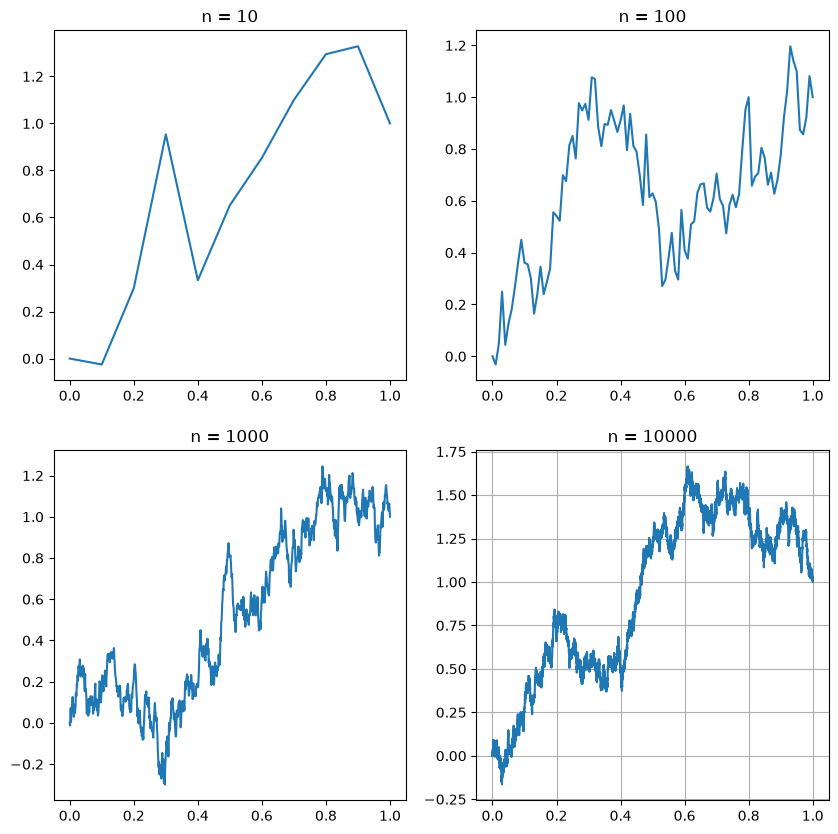

In [11]:
n = [10, 100, 1000, 10000]
P = [puente_brown(i, 0, 1, seed = 29) for i in n]

fig, axes = plt.subplots(2, 2, figsize = (10, 10))
for i in range(2):
    for j in range(2):
        k = 2*i + j
        t = np.linspace(0, T, n[k] + 1)
        axes[i, j].plot(t, P[k])
        axes[i, j].set_title(f'n = {n[k]}')
plt.grid()
plt.show()

## (c) Considera el proceso

## $$ X_t = a + \frac{b-a}{T}\,t + B_t - \frac{t}{T}\,B_T, \qquad t \in [0, T]. $$

## Muestra que $X_t$ es un proceso gaussiano con la misma función de medias y de covarianzas obtenidas en el inciso (a). Concluye que este proceso tiene las mismas distribuciones finito-dimensionales que el puente Browniano. Implementa un segundo algoritmo de simulación utilizando esta representación.

Sea $t \in [0,T]$ fija, entonces claramente podemos ver que es un proceso gausiano, pues si tomamos $B = (B_t, B_T)$,  $A = (1, -\frac{t}{T})$ y finalemente $c = a + \frac{b-a}{T}\,t $, entonces $X_t = a + \frac{b-a}{T}\,t + B_t - \frac{t}{T}\,B_T = c + A^tB \sim \text{N}(c, A^t\Sigma A)$

Ahora calculemos su media,

$$\mathbb{E}[X_t] = c = a + \frac{b-a}{T}\,t$$

y covarianza

$$\mathbb{Cov}(X_s, X_t) = \mathbb{Cov}(a + \frac{b-a}{T}\, s + B_s - \frac{s}{T}\,B_T, a + \frac{b-a}{T}\,t + B_t - \frac{t}{T}\,B_T) = \mathbb{Cov}(B_s - \frac{s}{T}\,B_T, B_t - \frac{t}{T}\,B_T) $$
$$ = \mathbb{Cov}(B_s, B_t) - \frac{s}{T}\mathbb{Cov}(B_T, B_t) - \frac{t}{T}\mathbb{Cov}(B_s, B_T) + \frac{st}{T^2} \mathbb{Cov}(B_T, B_T) = \min\{s, t\} - \frac{s}{T}\,t - \frac{t}{T}\,s + \frac{st}{T^2}\,T $$
$$ = \min\{s, t\} - \frac{2st}{T} + \frac{st}{T} = \min\{s, t\} - \frac{st}{T}.$$

Sabemos que el puente browniano es un movimiento browniano condicionado a terminar en cierto punto b en el tiempo T, cuando empezamos en a. Entonces veamos que $X_0 = a + B_0 = a$ y $X_T = a +(b-a) + B_T - B_T = b$. 

In [12]:
def puente_browniano(n, a, b, T = 1, seed = None):
    if seed != None:
        np.random.seed(seed)
    t = np.linspace(0, T, n + 1)
    B = browniano_estandar(n, T)
    P = a + (b - a) * t / T + B - (t / T) * B[-1]
    return P

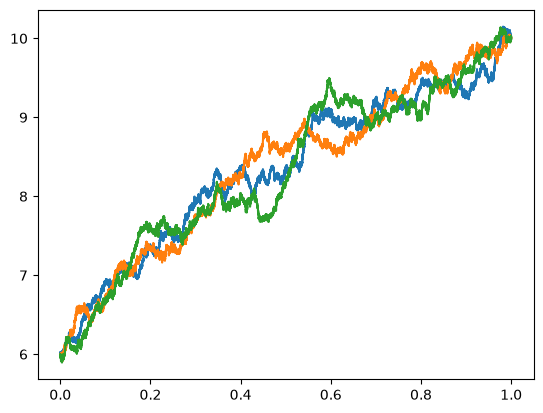

In [13]:
for i in range(3):
    puente = puente_browniano(100000, 6, 10, T, seed = 29 + i)
    plt.plot(np.linspace(0, T, 100001), puente)
plt.show()

## (d) Compara ambos algoritmos en términos de tiempo de ejecución y requerimientos computacionales conforme aumenta el número de puntos de la partición. ¿Qué ventajas y desventajas presenta cada procedimiento? Justifica tus conclusiones a partir de los algoritmos implementados.

In [14]:
import time

n = [10, 100, 1000, 10000]
for i in n:
    start_time = time.time()
    puente = puente_brown(i, 6, 10, T, seed = 29)
    end_time = time.time()
    print(f"Tiempo del algoritmo (a) para n = {i}: {end_time - start_time:.6f} segs")
    start_time = time.time()
    puente_2 = puente_browniano(i, 6, 10, T, seed = 29)
    end_time = time.time()
    print(f"Tiempo del algoritmo (c) para n = {i}: {end_time - start_time:.6f} segs")

Tiempo del algoritmo (a) para n = 10: 0.000000 segs
Tiempo del algoritmo (c) para n = 10: 0.000000 segs
Tiempo del algoritmo (a) para n = 100: 0.004018 segs
Tiempo del algoritmo (c) para n = 100: 0.000000 segs
Tiempo del algoritmo (a) para n = 1000: 1.012949 segs
Tiempo del algoritmo (c) para n = 1000: 0.000000 segs
Tiempo del algoritmo (a) para n = 10000: 68.682886 segs
Tiempo del algoritmo (c) para n = 10000: 0.000519 segs


Podemos notar que el tiempo de ejecucion para el algoritmo visto en el inciso (c) es muchisimo mas rapido. Esto pues el algortimo (a) utiliza la descomposición de Cholesky, el cual es computacionalmente muy costoso. Pero el algortimo (c) en vez de usar la descomposicion, calcula n distribuciones normales, lo cual computacionalmente, es muchisimo mas rapido.

# 3. Considera el movimiento Browniano geométrico definido por la ecuación diferencial estocástica

# $$ dX_t = \mu X_t\,dt + \sigma X_t\,dB_t, \qquad X_0 = x_0 > 0, $$

# donde $\mu \in \mathbb{R}$, $\sigma > 0$ y $\{B_t : t \geq 0\}$ es un movimiento Browniano estándar.

# Realiza lo siguiente:

## (a) Utilizando la fórmula de Itô, muestra que la solución de la ecuación diferencial estocástica está dada por

## $$ X_t = x_0 \exp\left[\left(\mu - \frac{\sigma^2}{2}\right)t + \sigma B_t\right]. $$

## Obtén además $\mathbb{E}[X_t]$ y $\operatorname{Var}(X_t)$.

Consideremos $f(t, B(t)) = x_0 \exp{[(\mu - \frac{\sigma^2}{2})\,t + \sigma B(t)]}$, con lo cual tendremos que 

$$f_t(t, B(t)) = (\mu - \frac{\sigma^2}{2})f, \qquad f_b(t, B(t)) = \sigma f, \qquad f_{xx}(t, B(t)) = \sigma^2 f$$

Entonces con la formula de Ito tenemos que,

$$dX_t = df(t, X(t)) = (\mu - \frac{\sigma^2}{2})\,f dt + \sigma f dB_t + \frac{\sigma^2}{2} f (dB_t)^2.$$

Como $dB_t dB_t = dt$, entonces obtenemos que,

$$dX_t = \mu f dt + \sigma f dB_t,$$

con lo cual, $X_t$ es soluciones dela ecuación.


Ahora, 

$$\mathbb{E}[X_t] = x_0\exp\{(\mu-\frac{\sigma^2}{2})t\} \mathbb{E}[e^{\sigma B_t}],$$

pero como $\mathbb{E}[e^{\sigma B_t}]$, es la funcion generadora de momentos de $B_t$ entonces tendremos $M_{B_t}(\sigma) = e^{\frac{\sigma^2 t}{2}}$, tendremos que la esperanza será:

$$\mathbb{E}[X_t] = x_0\exp\{(\mu-\frac{\sigma^2}{2})t + \frac{\sigma^2 t}{2}\} = x_0 e^{\mu t}.$$


Para la varianza primero calculemos el segundo momento de $X_t$, la cual será

$$\mathbb{E}[X_t^2] = x_0^2\exp\{2(\mu-\frac{\sigma^2}{2})t\} \mathbb{E}[e^{2 \sigma B_t}] = x_0^2\exp\{2(\mu-\frac{\sigma^2}{2})t + \frac{4 \sigma^2 t}{2}\} = x_0^2 \exp\{2\mu t + \sigma^2 t\}.$$

Así que la varianza será,

$$\operatorname{Var}(X_T) = \mathbb{E}[X_t^2] - \mathbb{E}^2[X_t] = x_0^2 \exp\{2\mu t + \sigma^2 t\} - x_0^2 e^{2 \mu t} = x_0^2 e^{2 \mu t}(e^{\sigma^2 t} -1)$$

## (b) Considera una partición uniforme $0 = t_0 < t_1 < ... < t_n = T$, con $\Delta t = T/n$. Obtén las aproximaciones de Euler–Maruyama y Milstein para esta ecuación diferencial estocástica.

Tendremos que la aproximacion de Euler-Maruyama será

$$X_{i+1} = X_i + \mu X_i \Delta t_i + \sigma X_i \Delta B_i$$

y la aproximacion de Milstein

$$X_{i+1} = X_i + \mu X_i \Delta t_i + \sigma X_i \Delta B_i + \frac{1}{2}\sigma^2X_i((\Delta B_i)^2 - \Delta t_i)$$

In [15]:
def Euler_Maruyama_geom(n, mu, sigma, X0 = 1, T = 1, seed = None):
    if seed != None:
        np.random.seed(seed)
    dt = T / n
    dB = np.sqrt(dt) * np.random.randn(n)
    X = np.zeros(n + 1)
    X[0] = X0
    for i in range(n):
        X[i +1] = X[i] + mu*X[i]*dt + sigma*X[i]*dB[i]
    return X

def Milstein_geom(n, mu, sigma, X0 = 1, T = 1, seed=None):
    if seed != None:
        np.random.seed(seed)
    dt = T/n
    dB = np.sqrt(T/n) *np.random.randn(n)
    X = np.zeros(n + 1)
    X[0] = X0
    for i in range(n):
        X[i + 1] = X[i] + mu*X[i]*dt + sigma*X[i]*dB[i] + 0.5*(sigma**2)*X[i]*(dB[i]**2 - dt)
    return X

In [16]:
Euler = Euler_Maruyama_geom(10000, 0.1, 0.2, X0 = 1, T = 1, seed = 29)
Milstein = Milstein_geom(10000, 0.1, 0.2, X0 = 1, T = 1, seed = 29)

Euler[-10:], Milstein[-10:]

(array([1.58660084, 1.59096846, 1.58586814, 1.58809118, 1.59416112,
        1.59702899, 1.59424668, 1.59286927, 1.59087545, 1.58801762]),
 array([1.58691319, 1.59128446, 1.58618818, 1.58841003, 1.59448955,
        1.59735738, 1.59457375, 1.59319348, 1.59119734, 1.58833834]))

## (c) ¿Puedes garantizar la positividad de la aproximación al movimiento browniano geométrico con estos métodos?

En ninguno de los dos casos se puede asegurar la positividad, ya que, en el caso de Euler-Maruyama tendremos

$$X_{i+1} = X_i(1 + \mu dt_i + \sigma dB_i),$$

entonces si ocurre que $dB_i < - \frac{1 + \mu dt_i}{\sigma}$ tendremos que $X_{i+1} < 0$, lo cual puede ocurrir, ya que $dB_i \sim \text{N}(0, \frac{T}{n})$ y si bien, para $\mu$ muy grande y $\sigma$ pequeña hay menos probabilidad de que ocurra, siempre puede ocurrir

En el caso de Milstein, tambien no podemos asegurar nada, ya que, como

$$X_{i+1} = X_i(1 + \mu \Delta t_i + \sigma \Delta B_i + \frac{\sigma^2}{2}(\Delta B_i^2 - \Delta t_i))$$

Aqui vemos que si $\Delta B_i < - \frac{1 + \mu \Delta t_i + \frac{\sigma^2}{2}(\Delta B_i^2 - \Delta t_i)}{\sigma}$, pero ahora veamos si esto puede ocurrir. Si derivamos $X_{i+1}$ respecto de $\Delta B_i$ tendremos, 

$$X'_i=X'_i\sigma + \sigma^2\Delta B_i) = 0 \quad \rightarrow \quad \Delta B_i = - \frac{1}{\sigma}$$

sera el minimo, y como el termino en parentesis es una parabola que abre para arriba, si llegara a ser negativa en algun momento, tendría que serlo en el minimo. Entonces sustituyendo el minimo tenemos

$$1 + \mu \Delta t_i + \sigma (- \frac{1}{\sigma}) + \frac{\sigma^2}{2}((- \frac{1}{\sigma})^2 - \Delta t_i) = 1 + \mu \Delta t_i - 1 + \frac{1}{2} + \frac{\sigma^2}{2}\Delta t_i = \frac{1}{2} + \mu \Delta t_i - \frac{\sigma^2}{2}\Delta t_i = \frac{1}{2} + (\mu - \frac{\sigma^2}{2})\Delta t_i$$

Así que si $\frac{1}{2} + (\mu - \frac{\sigma^2}{2})\Delta t_i < 0$, entonces habran posibles valores de $B_t$ que hagan que $X_{t_i}$ sea negativo.

# 4. Considera el proceso de Ornstein–Uhlenbeck definido por la ecuación diferencial estocástica

# $$ dX_t = (\theta_1 - \theta_2 X_t)\,dt + \theta_3\,dB_t, $$

# donde $\theta_1 \in \mathbb{R}$, $\theta_2, \theta_3 > 0$, $X_0 = x_0 \in \mathbb{R}$ y $\{B_t : t \geq 0\}$ es un movimiento Browniano estándar.

# Realiza lo siguiente:

## (a) Utilizando la fórmula de Itô, se tiene que la solución está dada por

## $$ X_t = x_0 e^{-\theta_2 t} + \frac{\theta_1}{\theta_2}\left(1 - e^{-\theta_2 t}\right) + \theta_3 \int_0^t e^{-\theta_2 (t-s)}\,dB_s. $$

## A partir de esta expresión, obtén la distribución condicional de $X_t$ dado $X_s = x$, para $0 \leq s < t$.

Sea $X_s = x$, entonces tenemos que

$$X_t = x_0 e^{-\theta_2 t} + \frac{\theta_1}{\theta_2}(1 - e^{-\theta_2 t}) + \theta_3 \int_0^t e^{-\theta_2 (t-s)}\,dB_s = x_0e^{-\theta_2s}e^{-\theta_2(t-s)} + \frac{\theta_1}{\theta_2}(1 - e^{-\theta_2 s}e^{-\theta_2(t-s)})  + \theta_3 \int_0^t e^{-\theta_2 (t-u)}\,dB_u.$$

Donde

$$\int_0^t e^{-\theta_2 (t-u)}\,dB_u = \int_0^s e^{-\theta_2 (t-u)}\,dB_u + \int_s^t e^{-\theta_2 (t-u)}\,dB_u = \int_0^s e^{-\theta_2 (t-s)}e^{-\theta_2 (s/u)}\,dB_u + \int_s^t e^{-\theta_2 (t-u)}\,dB_u,$$

entonces parecieera que $X_s$ esta oculto por ahí, así que reorganizando obtenemos

$$X_t = [x_0e^{-\theta_2s}e^{-\theta_2(t-s)} + \frac{\theta_1}{\theta_2}(1 - e^{-\theta_2 s})e^{-\theta_2(t-s)} + e^{-\theta_2 (t-s)}\theta_3\int_0^s e^{-\theta_2 (s/u)}\,dB_u] - \frac{\theta_1}{\theta_2}(1 - e^{-\theta_2 s})e^{-\theta_2(t-s)} $$
$$+ \frac{\theta_1}{\theta_2}(1 - e^{-\theta_2 s}e^{-\theta_2(t-s)}) + \theta_3 \int_s^t e^{-\theta_2 (t-u)}\,dB_u = e^{-\theta_2(t-s)}\,X_s + \frac{\theta_1}{\theta_2}(1 - e^{-\theta_2(t-s)}) + \theta_3 \int_s^t e^{-\theta_2 (t-u)}\,dB_u.$$

Condicionando obtenemos

$$X_t|X_s = xe^{-\theta_2(t-s)} + \frac{\theta_1}{\theta_2}(1 - e^{-\theta_2(t-s)}) + \theta_3 \int_s^t e^{-\theta_2 (t-u)}\,dB_u = xe^{-\theta_2(t-s)} + \frac{\theta_1}{\theta_2}(1 - e^{-\theta_2(t-s)}) + $$
$$\theta_3 \int_0^{t-s} e^{-\theta_2 (t-u)}\,dB_u \sim X_{t-s} \sim \mathcal{N}\left( x e^{-\theta_2 (t-s)} + \frac{\theta_1}{\theta_2}\left(1 - e^{-\theta_2 (t-s)}\right),\ \frac{\theta_3^2}{2\theta_2}\left(1 - e^{-2\theta_2 (t-s)}\right) \right)$$

## (b) Utilizando la distribución condicional obtenida en el inciso anterior, implementa un algoritmo que permita simular trayectorias del proceso de Ornstein–Uhlenbeck en el intervalo $[0, T]$, considerando una partición uniforme de $n$ subintervalos.

In [17]:
def Ornstein_Uhlenbeck(n, theta, X0 = 0, T = 1, seed = None):
    if seed != None:
        np.random.seed(seed)
    X = np.zeros(n + 1)
    theta_1 = theta[0]
    theta_2 = theta[1]
    theta_3 = theta[2]
    X[0] = X0
    dt = T/n
    for i in range(n):
        X[i+1] = np.sqrt(theta_3**2 / (2 * theta_2) *(1 - np.exp(-2 * theta_2 * dt))) *np.random.randn() + np.exp(-theta_2 * dt) * X[i] + theta_1 / theta_2 * (1 - np.exp(-theta_2 * dt))
    return X

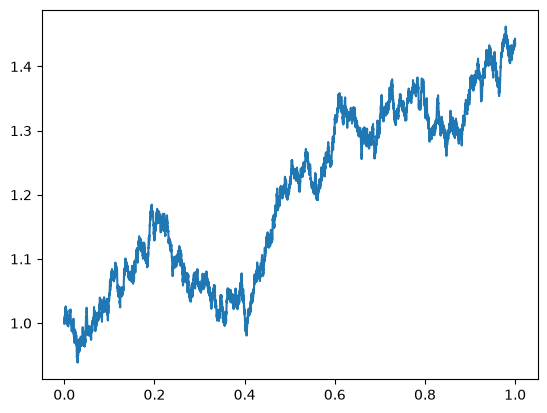

In [22]:
Orn_Uhl = Ornstein_Uhlenbeck(10000, [0.1, 0.2, 0.3], X0 = 1, T = 1, seed = 29)
plt.plot(np.linspace(0, 1, 10001), Orn_Uhl)
plt.show()

## (c) Obtén la aproximación de Euler–Maruyama para este proceso. Para $T = 5$, $\theta_1 = 3$, $\theta_2 = 2$, $\theta_3 = 1$ y $x_0 = 0$, genera trayectorias utilizando ambos algoritmos para $n = 10, 50, 100, 500$. Compara gráficamente las trayectorias obtenidas y discute las diferencias observadas conforme aumenta $n$.

Tendremos 

$$X_{i+1} = X_i + (\theta_1 - \theta_2 X_i)\,\Delta t + \theta_3\,\Delta B_t,$$

In [23]:
def Euler_Maruyama_orn(n, theta, X0 = 1, T = 1, seed = None):
    if seed != None:
        np.random.seed(seed)
    dt = T/n
    dB = np.sqrt(dt) * np.random.randn(n)
    theta_1 = theta[0]
    theta_2 = theta[1]
    theta_3 = theta[2]
    X = np.zeros(n + 1)
    X[0] = X0
    for i in range(n):
        X[i +1] = X[i] + (theta_1 - theta_2*X[i]) * dt + theta_3 * dB[i]
    return X

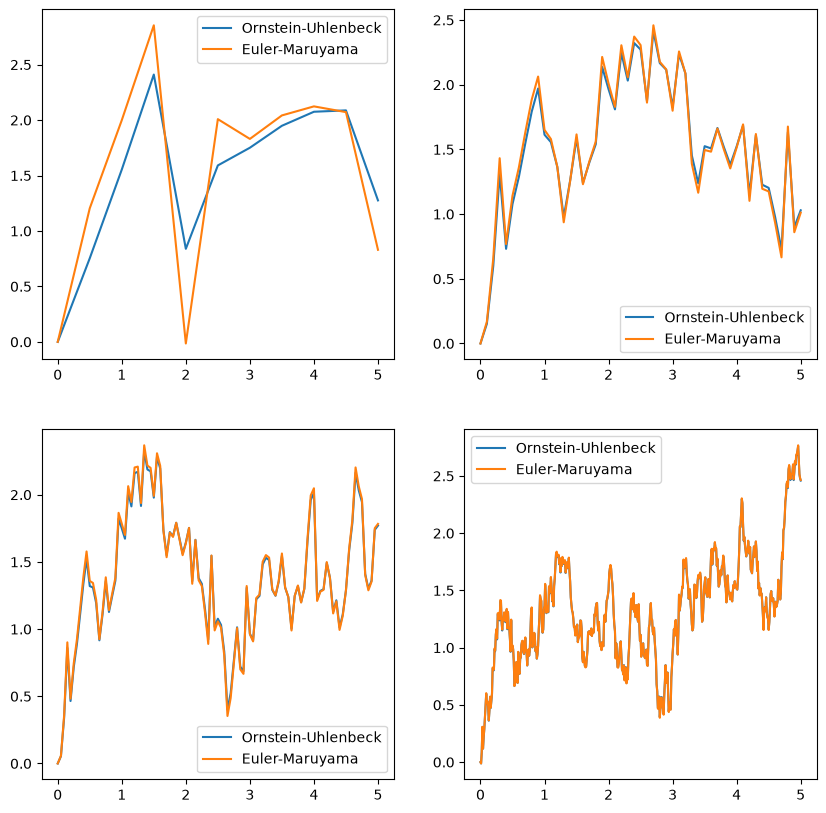

In [28]:
n = [10, 50, 100, 500]
fig, axes = plt.subplots(2, 2, figsize = (10, 10))

for i in n:
    Orn_Uhl = Ornstein_Uhlenbeck(i, [3, 2, 1], X0 = 0, T = 5, seed = 29)
    Euler = Euler_Maruyama_orn(i, [3, 2, 1], X0 = 0, T = 5, seed = 29)
    axes[(n.index(i))//2, (n.index(i))%2].plot(np.linspace(0, 5, i + 1), Orn_Uhl, label = 'Ornstein-Uhlenbeck')
    axes[(n.index(i))//2, (n.index(i))%2].plot(np.linspace(0, 5, i + 1), Euler, label = 'Euler-Maruyama')
    axes[(n.index(i))//2, (n.index(i))%2].legend()
plt.show()




Pareciera que mientras n es chica, ambos metodo no obtuvieran resultados tan similares, pero a medida que aumenta n, ambos metodos parecieran producir el mismo resultado.

## (d) Muestra que la aproximación de Euler–Maruyama puede escribirse como un proceso autorregresivo de orden uno, AR(1). Obtén la condición sobre $\Delta t = T/n$ que garantiza su estabilidad y estudia qué ocurre cuando dicha condición no se satisface.

De Euler_Maruyama teníamaos que 

$$X_{i+1} = X_i + (\theta_1 - \theta_2 X_i)\,\Delta t + \theta_3\,\Delta B_t = \theta_1 \Delta t + (1 - \theta_2 \Delta t)X_i + \theta_t \sqrt{\Delta t} Z_t.$$

Donde $Z_t \sim RB(0, 1)$. Ahora para un AR(1) de la forma $X_{i+1} = c + \phi X_i + \theta Z_i$ es estable, si $|\phi| < 1$, así que necesitamos que 

$|(1 - \theta_2 \Delta t)| < 1 \qquad \rightarrow \qquad 0 < \Delta t < \frac{2}{\theta_2}.$

Ahora veamos que pasa si $\Delta t > \frac{2}{\theta_2}$.

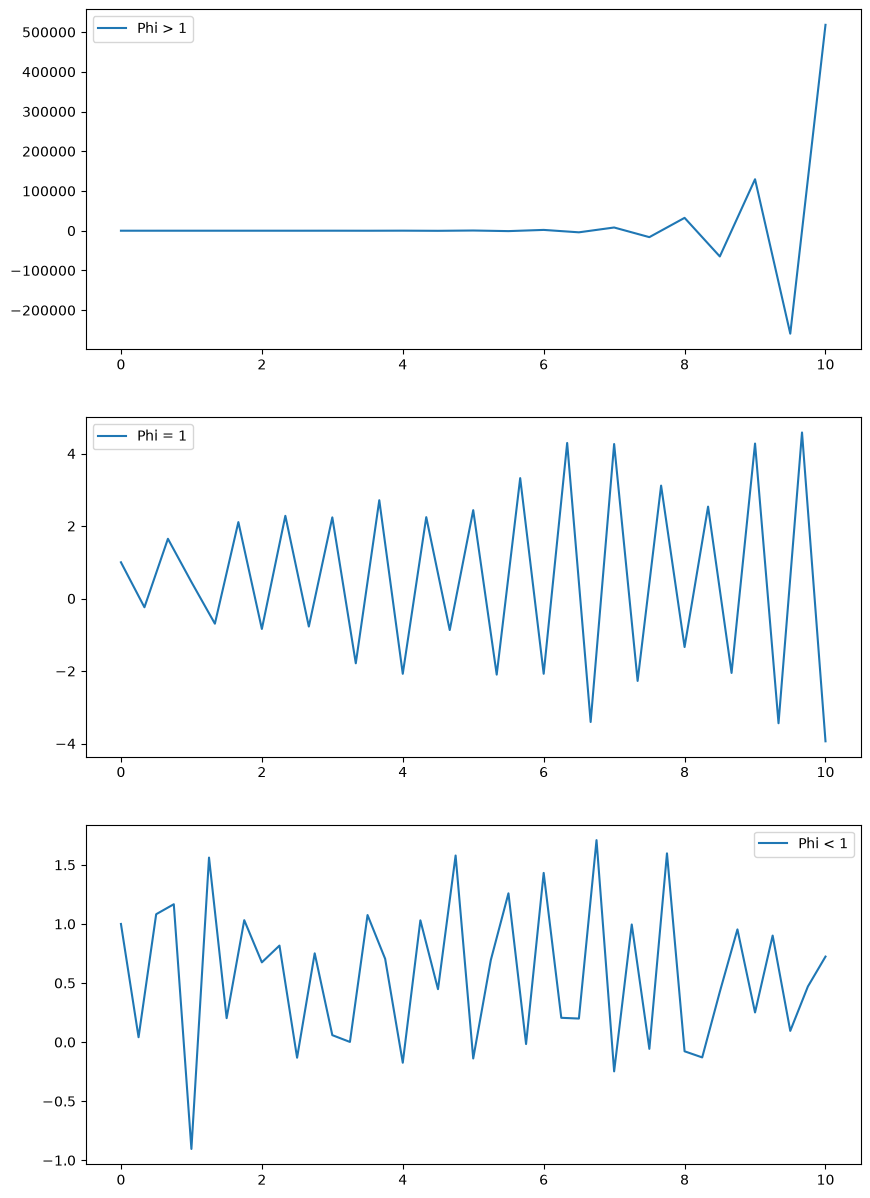

In [34]:
Euler_orn_phi_mayor = Euler_Maruyama_orn(20, [3, 6, 1], X0 = 1, T = 10, seed = 29)
Euler_orn_phi_igual = Euler_Maruyama_orn(30, [3, 6, 1], X0 = 1, T = 10, seed = 29)
Euler_orn_phi_menor = Euler_Maruyama_orn(40, [3, 6, 1], X0 = 1, T = 10, seed = 29)
fig, axes = plt.subplots(3, 1, figsize = (10, 15))
axes[0].plot(np.linspace(0, 10, 21), Euler_orn_phi_mayor, label = 'Phi > 1')
axes[1].plot(np.linspace(0, 10, 31), Euler_orn_phi_igual, label = 'Phi = 1')
axes[2].plot(np.linspace(0, 10, 41), Euler_orn_phi_menor, label = 'Phi < 1')
axes[0].legend()
axes[1].legend()
axes[2].legend()
plt.show()

En el caso en que $|\phi| > 1$ la varianza pareciera creecer de manera exponencial, mientras que en el caso en que $|\phi| = 1$, la varienza tambien pareceiera ser mayor que cuando no, aunque pareciera aumentar de manera menos acelerada que en el caso anterior.

## (e) Finalmente, compara la media y la varianza estacionarias de la aproximación de Euler–Maruyama con las correspondientes al proceso de Ornstein–Uhlenbeck.

Primero veamos que pasa con el caso limite $\lim \limits_{t \to \infty} X_t$, pero como sabemos que $X_t \sim \mathcal{N}( x_0 e^{-\theta_2 t} + \frac{\theta_1}{\theta_2}(1 - e^{-\theta_2 t}), \frac{\theta_3^2}{2\theta_2}(1 - e^{-2\theta_2 t}))$, entonces

$$\lim \limits_{t \to \infty} X_t \sim \mathcal{N}(\frac{\theta_1}{\theta_2}, \frac{\theta_3^2}{2\theta_2})$$

In [40]:
theta = [3, 2, 1]
n =10000000
dt = 5 / n

mu_OU = theta[0] / theta[1]
var_OU = theta[2]**2 / (2 * theta[1])

X_em = Euler_Maruyama_orn(n, theta, X0=1, T=1000, seed=29)

print("Teorico: media =", mu_OU, " var =", var_OU)
print("Euler: media =", X_em.mean(), " var =", X_em.var())

Teorico: media = 1.5  var = 0.25
Euler: media = 1.5336404404558042  var = 0.23964608920218974
